# Question 2 — Motion or Memory?
Hasan Amjad (25280042)

In [1]:
%load_ext autoreload
%autoreload 2
import platform, time, torch
from q2.common import *
from q2.transforms import *
from q2.models import *

DEVICE = get_device()
print("torch", torch.__version__, "| device:", DEVICE, "|", platform.platform(), platform.processor())

torch 2.15.0 | device: mps | macOS-27.0.1-arm64-arm-64bit arm


## 1. Setup
### Table 1 — checks

In [2]:
from q2.checks import run_table1, print_table1
table1 = run_table1()
print_table1(table1)
save_json(table1, "table1.json");

    Check                                      Expected                                Yours
(a) max|M(M(x)) - x|                           0                                       0 (torch.equal: True)  [OK ]
(b) max|R^4(x) - x|                            0                                       0 (torch.equal: True)  [OK ]
(c) max|M R M(x) - R^-1(x)|                    0                                       0 (torch.equal: True)  [OK ]
(d) bright pixel of M(p) (frame, row, column)  (7, 10, 43)                             (7, 10, 43)  [OK ]
(e) bright pixel of R(p) (frame, row, column)  (7, 43, 10)                             (7, 43, 10)  [OK ]
(f) 1x input / target frames                   1, 2, 3, 4, 5 / 6, 7, 8, 9, 10          1, 2, 3, 4, 5 / 6, 7, 8, 9, 10  [OK ]
(g) 2x input / target frames                   1, 3, 5, 7, 9 / 11, 13, 15, 17, 19      1, 3, 5, 7, 9 / 11, 13, 15, 17, 19  [OK ]
(h) 3x input / target frames                   1, 4, 7, 10, 13 / 16, 19                1, 4, 

### Data

In [3]:
data = load_moving_mnist()
train_u8, val_u8, test_u8 = splits(data)
print("all", tuple(data.shape), data.dtype, "| train", len(train_u8), "| val", len(val_u8), "| test", len(test_u8))

all (10000, 20, 1, 64, 64) torch.uint8 | train 8000 | val 1000 | test 1000


### Figure 1 — training-data motion

pairs = 950, pixels kept = 103,050, median speed = 3.32 px/frame
2x -> 6.635 px/frame;  3x -> 9.953 px/frame
direction fractions per 20-degree bin: [0.049, 0.0488, 0.0675, 0.0731, 0.0602, 0.0561, 0.0263, 0.0326, 0.0384, 0.082, 0.0642, 0.0541, 0.0666, 0.0614, 0.0571, 0.0366, 0.0487, 0.0772]


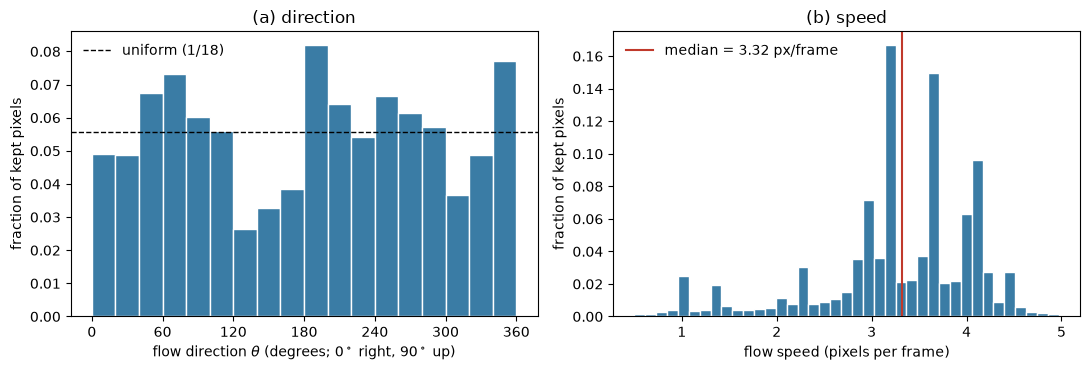

In [4]:
from q2.flow import pooled_flow, figure1
dx, dy, n_pairs = pooled_flow(train_u8, n_videos=50)
fig, fig1_stats = figure1(dx, dy, FIG_DIR / "fig1_flow_stats.png")
fig1_stats["n_pairs"] = n_pairs
save_json(fig1_stats, "fig1_stats.json")
print(f"pairs = {n_pairs}, pixels kept = {fig1_stats['n_pixels']:,}, median speed = {fig1_stats['median_speed']:.3g} px/frame")
print("2x ->", round(2*fig1_stats['median_speed'], 3), "px/frame;  3x ->", round(3*fig1_stats['median_speed'], 3), "px/frame")
print("direction fractions per 20-degree bin:", fig1_stats["direction_fractions"])

### Model A — parameter count

In [5]:
mA = model_A()
print("model A params:", n_params(mA))
assert n_params(mA) == 480_784
with torch.no_grad():
    out = mA(torch.rand(2, 5, 1, 64, 64))
print("output shape:", tuple(out.shape))

model A params: 480784
output shape: (2, 5, 1, 64, 64)


## 2. Baseline: ConvLSTM
Training: `python -m q2.train --model A` (seeds 0, 1).

A s0: final val E(5) 2.247e-02, mean epoch 24.8s
A s1: final val E(5) 2.154e-02, mean epoch 26.4s


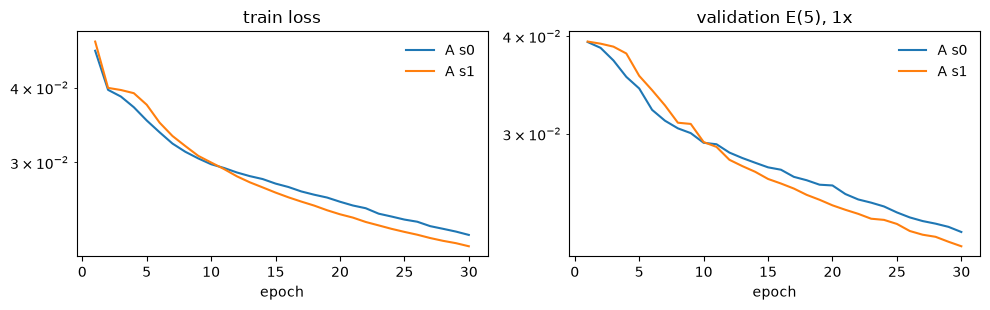

In [6]:
import matplotlib.pyplot as plt

def plot_training(names, seeds=(0, 1), path=None):
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
    for n in names:
        for s in seeds:
            h = load_json(f"train_{n}_s{s}.json")
            ep = range(1, len(h["train_loss"]) + 1)
            ax[0].plot(ep, h["train_loss"], label=f"{n} s{s}")
            ax[1].plot(ep, h["val_e5"], label=f"{n} s{s}")
            print(f"{n} s{s}: final val E(5) {h['val_e5'][-1]:.3e}, mean epoch {h['mean_epoch_time']:.1f}s")
    for a, t in zip(ax, ["train loss", "validation E(5), 1x"]):
        a.set_xlabel("epoch"); a.set_title(t); a.set_yscale("log"); a.legend(frameon=False)
    fig.tight_layout()
    if path: fig.savefig(path, dpi=150, bbox_inches="tight")

plot_training(["A"])

In [7]:
import numpy as np, pandas as pd
from q2.evaluate import *
from q2 import visuals as V

W = test_windows(test_u8)
X1, Y1, _ = W[1]
SEEDS = (0, 1)
res, pv, preds = {}, {}, {}
for name, mdl in [("Blank", Blank()), ("Copy-last", CopyLast())]:
    res[name], pv[name], preds[name] = evaluate(mdl.to(DEVICE), W)
for sd in SEEDS:
    res[f"A_s{sd}"], pv[f"A_s{sd}"], preds[f"A_s{sd}"] = evaluate(load_model("A", sd), W)
save_json(res, "metrics_A.json")

PosixPath('/Users/hasanamjad/Documents/MS AI/AI 651 DL Time Space/DL4STG_PA2 2/Question2/results/metrics_A.json')

### Table 2

In [8]:
def vals(name, key):
    return [res[f"{name}_s{s}"][key] for s in SEEDS] if f"{name}_s0" in res else [res[name][key]]

rows = {}
for name, params in [("A", n_params(model_A())), ("Blank", 0), ("Copy-last", 0)]:
    r = {f"MSE{h+1}": cell([v[h] for v in vals(name, "MSE_h")]) for h in range(5)}
    r["E(5)"] = cell(vals(name, "E5_1x")); r["params"] = f"{params:,}"
    rows[name] = r
table2 = pd.DataFrame(rows).T; table2

,MSE1,MSE2,MSE3,MSE4,MSE5,E(5),params
A,"0.0172 (0.0176, 0.0167)","0.0205 (0.021, 0.02)","0.0228 (0.0233, 0.0222)","0.0244 (0.025, 0.0238)","0.026 (0.0266, 0.0255)","0.0222 (0.0227, 0.0216)","480,784"
Blank,0.0426,0.0426,0.0426,0.0425,0.0425,0.0426,0
Copy-last,0.0492,0.0604,0.0669,0.0708,0.0732,0.0641,0


### Figure 2

videos: [9000, 9007, 9012]


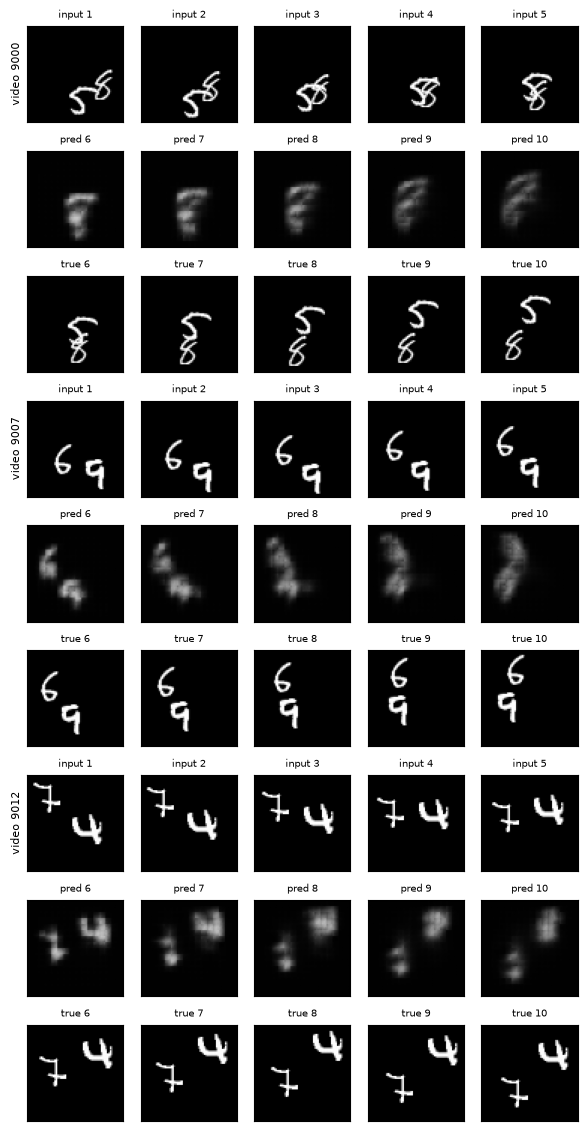

In [9]:
vt = to_float(test_u8)
n_ov = [V.overlap_frames(vt[i], range(1, 6)) for i in range(len(vt))]
merge_then_split = [i for i in range(len(vt)) if n_ov[i] >= 3 and V.separated(vt[i], [9, 10])]
fig2_ids = [max(merge_then_split, key=lambda i: n_ov[i])] + [i for i in range(len(vt)) if V.overlap_frames(vt[i], range(1, 11)) == 0][:2]
print("videos:", [9000 + i for i in fig2_ids])
V.figure2(X1, Y1, preds["A_s0"]["I"], fig2_ids, FIG_DIR / "fig2_A_predictions.png");

## 3. Testing the baseline
### Table 3

In [10]:
rows = {}
for name in ["A", "Blank", "Copy-last"]:
    rows[name] = {k: cell(vals(name, key)) for k, key in
                  [("E(5)", "E5_1x"), ("C_M", "C_M"), ("E_M", "E_M"), ("C_R", "C_R"), ("E_R", "E_R")]}
table3 = pd.DataFrame(rows).T; table3

,E(5),C_M,E_M,C_R,E_R
A,"0.0222 (0.0227, 0.0216)","0.00176 (0.00158, 0.00195)","0.0228 (0.0233, 0.0223)","0.00289 (0.0026, 0.00318)","0.0239 (0.0242, 0.0236)"
Blank,0.0426,0,0.0426,0,0.0426
Copy-last,0.0641,0,0.0641,0,0.0641


### Figure 3

{'C_M': [980, 269], 'C_R': [925, 513]}


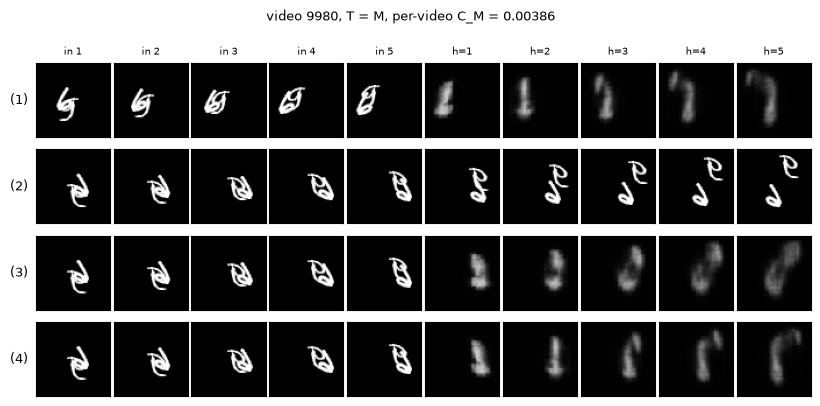

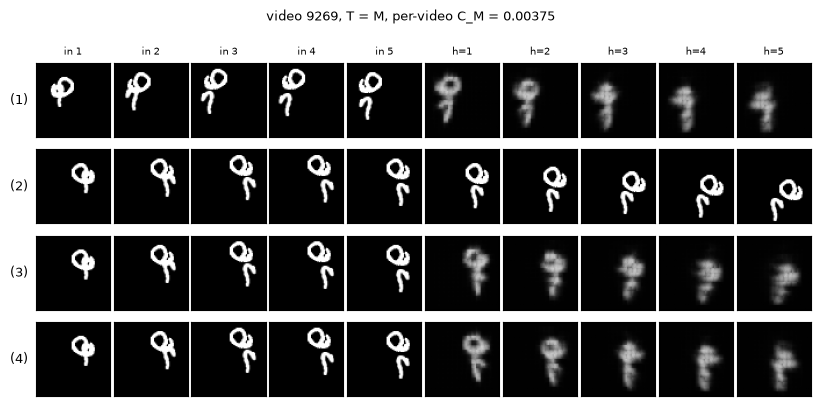

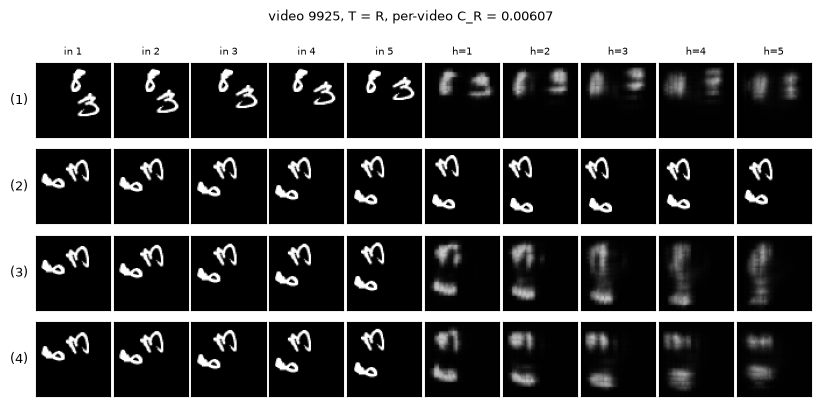

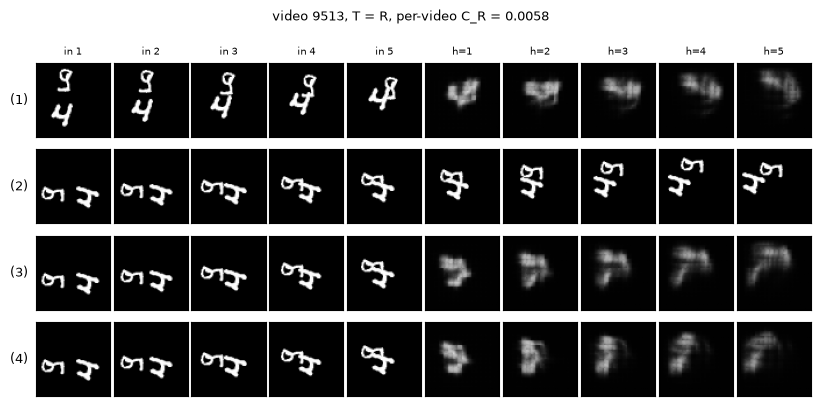

In [11]:
p0, P0 = pv["A_s0"], preds["A_s0"]
marks = {"C_M": np.argsort(-p0["C_M"])[:2].tolist(), "C_R": np.argsort(-p0["C_R"])[:2].tolist()}
for key, T in [("C_M", mirror), ("C_R", rotate)]:
    for n, i in enumerate(marks[key]):
        rows4 = V.four_rows(X1[i], Y1[i], P0["I"][i], P0[key[-1]][i], T)
        label = f"video {9000+i}, T = {key[-1]}, per-video {key} = {fmt(float(p0[key][i]))}"
        V.figure3_panel(rows4, label, FIG_DIR / f"fig3_A_{key[-1]}{n+1}_video{9000+i}.png")
        V.gif(rows4, GIF_DIR / f"fig3_A_{key[-1]}_video{9000+i}.gif")
print(marks)

### Figure 4

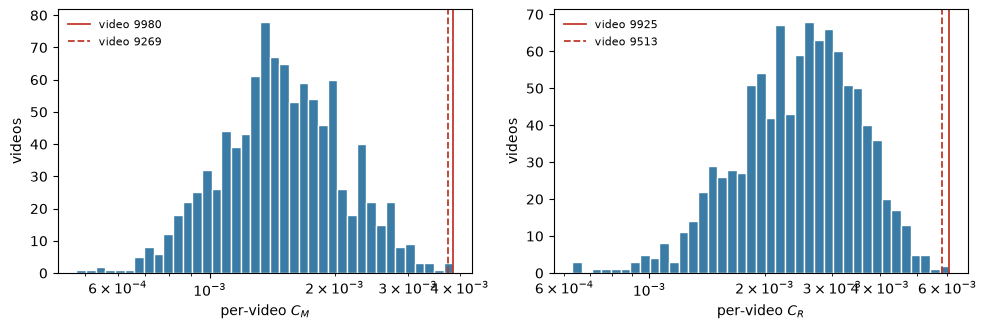

In [12]:
V.figure4(p0, marks, FIG_DIR / "fig4_A_consistency_hist.png");

### Table 4

In [13]:
rows = {}
for name in ["A", "Copy-last"]:
    rows[name] = {"E(2) 1x": cell(vals(name, "E2_1x")), "E(2) 2x": cell(vals(name, "E2_2x")),
                  "E(2) 3x": cell(vals(name, "E2_3x")), "E(5) 1x": cell(vals(name, "E5_1x")),
                  "E(5) 2x": cell(vals(name, "E5_2x"))}
table4 = pd.DataFrame(rows).T; table4

,E(2) 1x,E(2) 2x,E(2) 3x,E(5) 1x,E(5) 2x
A,"0.0189 (0.0193, 0.0184)","0.0444 (0.0431, 0.0457)","0.0522 (0.0511, 0.0533)","0.0222 (0.0227, 0.0216)","0.0488 (0.0467, 0.0509)"
Copy-last,0.0548,0.0661,0.0703,0.0641,0.0719


### Figure 5

video 9026 | digits apart in all frames: True


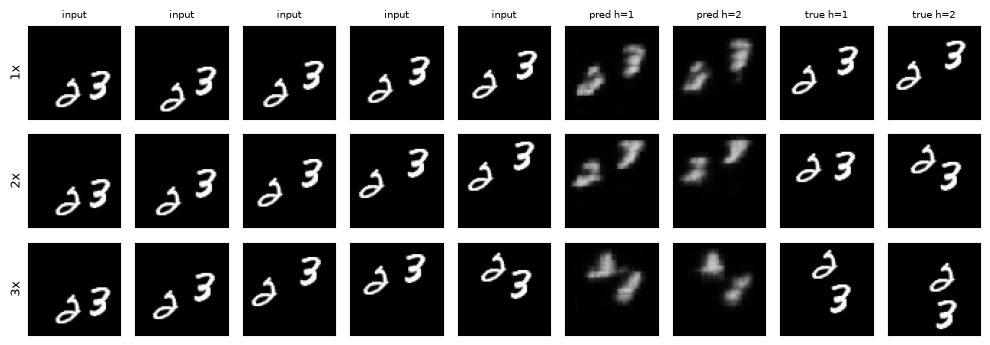

In [14]:
true_frames = [6, 7, 11, 13, 16, 19]
cands = [i for i in range(len(vt)) if V.separated(vt[i], true_frames)]
strict = [i for i in cands if V.separated(vt[i], range(1, 20))]
fig5_id = (strict or cands)[0]
print("video", 9000 + fig5_id, "| digits apart in all frames:", fig5_id in strict)
V.figure5(W, preds["A_s0"], fig5_id, FIG_DIR / "fig5_A_speed.png")
save_json({"fig2_ids": fig2_ids, "fig3_marks": marks, "fig5_id": fig5_id}, "figure_videos.json");

## 4. What can data fix?
### Model D selection (validation split, seed 0)

In [15]:
from q2.zoo import CONFIGS, D_CHOICE, reach_px, build
pd.DataFrame(load_json("d_selection.json")).T

,params,reach_px,val_E2_1x,val_E5_1x,val_E2_2x,val_E2_3x,val_E2_mean
C,480784.0,8.0,0.023704,0.027329,0.029309,0.033317,0.028777
Dd12,480784.0,12.0,0.024599,0.027642,0.029361,0.032261,0.028740
Dd13,480784.0,16.0,0.027556,0.030021,0.030940,0.033718,0.030738
Dk5,709520.0,16.0,0.039492,0.039470,0.039464,0.039457,0.039471


### Table 5

In [16]:
MODELS = ["A", "B", "C", "D"]
inf = {}
for name in MODELS:
    for sd in SEEDS:
        key = f"{name}_s{sd}"
        m = load_model(name, sd)
        if key not in res:
            r, p, pr = evaluate(m, W)
            res[key], pv[key] = r, p
            if sd == 0:
                preds[key] = pr
        inf[key] = inference_time(m, X1)
        res[key]["inference_s"] = inf[key]
        res[key]["train_epoch_s"] = load_json(f"train_{name}_s{sd}.json")["mean_epoch_time"]
save_json(res, "metrics_A-D.json")

cols = [("E(5) 1x", "E5_1x"), ("C_M", "C_M"), ("E_M", "E_M"), ("C_R", "C_R"), ("E_R", "E_R"),
        ("E(2) 1x", "E2_1x"), ("E(2) 2x", "E2_2x"), ("E(2) 3x", "E2_3x"),
        ("train s/epoch", "train_epoch_s"), ("inference s", "inference_s")]
rows = {}
for name in MODELS:
    r = {c: cell(vals(name, k)) for c, k in cols}
    r["params"] = f"{n_params(build(CONFIGS[name]['arch'])):,}"
    rows[name] = r
table5 = pd.DataFrame(rows).T; table5

,E(5) 1x,C_M,E_M,C_R,E_R,E(2) 1x,E(2) 2x,E(2) 3x,train s/epoch,inference s,params
A,"0.0222 (0.0227, 0.0216)","0.00176 (0.00158, 0.00195)","0.0228 (0.0233, 0.0223)","0.00289 (0.0026, 0.00318)","0.0239 (0.0242, 0.0236)","0.0189 (0.0193, 0.0184)","0.0444 (0.0431, 0.0457)","0.0522 (0.0511, 0.0533)","25.6 (24.8, 26.4)","0.721 (0.728, 0.713)","480,784"
B,"0.0228 (0.0235, 0.0221)","0.00121 (0.00125, 0.00117)","0.0228 (0.0235, 0.0221)","0.00141 (0.00156, 0.00126)","0.0227 (0.0233, 0.022)","0.0191 (0.0198, 0.0183)","0.0441 (0.0439, 0.0444)","0.0513 (0.0515, 0.0511)","24 (24.2, 23.9)","0.714 (0.711, 0.716)","480,784"
C,"0.0279 (0.0276, 0.0283)","7.94e-04 (7.99e-04, 7.89e-04)","0.0282 (0.0278, 0.0285)","0.00198 (0.00173, 0.00223)","0.0291 (0.0287, 0.0295)","0.0241 (0.0239, 0.0243)","0.0295 (0.0295, 0.0295)","0.0339 (0.0338, 0.034)","23.7 (23.6, 23.8)","0.711 (0.71, 0.711)","480,784"
D,"0.0275 (0.0279, 0.0272)","8.35e-04 (9.69e-04, 7.00e-04)","0.0277 (0.028, 0.0274)","0.00192 (0.00171, 0.00213)","0.0286 (0.0287, 0.0284)","0.0247 (0.0248, 0.0246)","0.0292 (0.0296, 0.0289)","0.0327 (0.0328, 0.0326)","27.9 (28, 27.7)","0.92 (0.924, 0.917)","480,784"


### Same clips across models

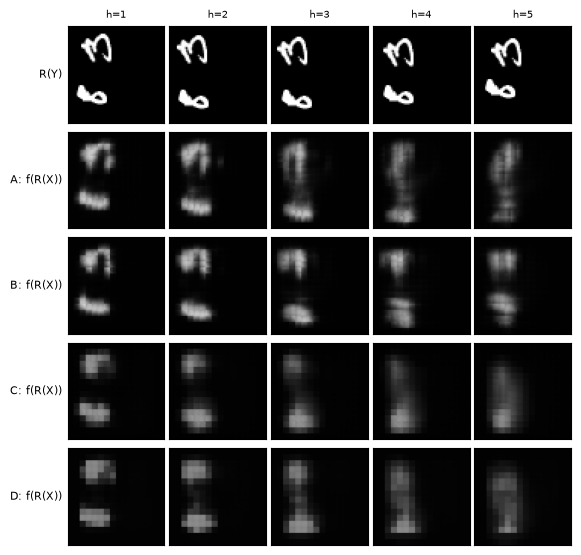

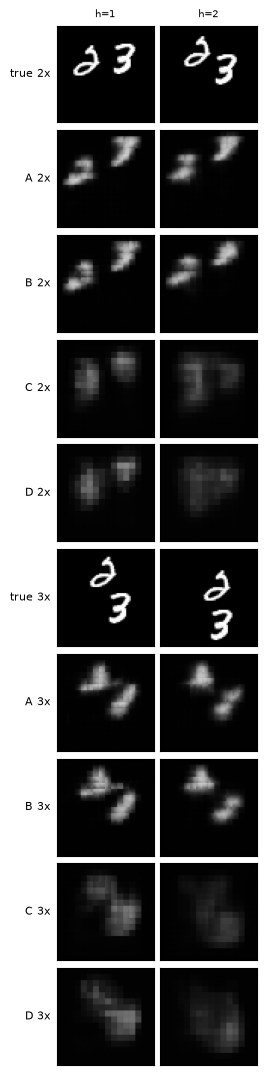

In [17]:
fv = load_json("figure_videos.json")
i_rot, i_spd = fv["fig3_marks"]["C_R"][0], fv["fig5_id"]
rows, names = [rotate(Y1[i_rot])], ["R(Y)"]
for name in MODELS:
    rows.append(preds[f"{name}_s0"]["R"][i_rot]); names.append(f"{name}: f(R(X))")
V.same_clips(rows, names, FIG_DIR / f"figS_rotation_video{9000+i_rot}.png")

rows, names = [], []
for k in (2, 3):
    rows.append(W[k][1][i_spd]); names.append(f"true {k}x")
    for name in MODELS:
        rows.append(preds[f"{name}_s0"][f"{k}x"][i_spd]); names.append(f"{name} {k}x")
V.same_clips(rows, names, FIG_DIR / f"figS_speed_video{9000+i_spd}.png", n_cols=2);

## 5. The final model
### Table 6

In [18]:
sel = load_json("final_selection.json")      # symmetrised D vs D+B on validation
print(pd.DataFrame({k: v for k, v in sel.items() if k != "choice"}).T, "\nchoice:", sel["choice"])
FINAL = sel["choice"].replace("sym", "")
wrapped = ["B", "D"] + ([FINAL] if FINAL not in ("B", "D") else [])
rows = {}
for name in wrapped:
    for sd in SEEDS:
        key = f"sym{name}_s{sd}"
        m = Symmetrised(load_model(name, sd)).eval()
        r, p, pr = evaluate(m, W)
        r["inference_s"] = inference_time(m, X1)
        r["train_epoch_s"] = load_json(f"train_{name}_s{sd}.json")["mean_epoch_time"]
        res[key], pv[key] = r, p
        if sd == 0:
            preds[key] = pr
    rows[f"sym-{name}"] = {c: cell(vals(f"sym{name}", k)) for c, k in cols}
    rows[f"sym-{name}"]["params"] = f"{n_params(build(CONFIGS[name]['arch'])):,}"
    for k in ("C_M", "C_R"):
        rows[f"sym-{name}"][k] = " ".join(f"{v:.2e}" for v in vals(f"sym{name}", k))
save_json({k: v for k, v in res.items() if k.startswith("sym")}, "metrics_sym.json")
table6 = pd.DataFrame(rows).T; table6

,E(5) 1x,C_M,E_M,C_R,E_R,E(2) 1x,E(2) 2x,E(2) 3x,train s/epoch,inference s,params
sym-B,"0.0221 (0.0228, 0.0215)",8.75e-17 7.46e-17,"0.0221 (0.0228, 0.0215)",7.14e-17 6.00e-17,"0.0221 (0.0228, 0.0215)","0.0186 (0.0194, 0.0179)","0.0434 (0.0432, 0.0436)","0.0503 (0.0505, 0.0501)","24 (24.2, 23.9)","5.03 (5.03, 5.03)","480,784"
sym-D,"0.0275 (0.0278, 0.0272)",5.08e-17 6.25e-17,"0.0275 (0.0278, 0.0272)",3.96e-17 4.84e-17,"0.0275 (0.0278, 0.0272)","0.0247 (0.0248, 0.0246)","0.0293 (0.0296, 0.0289)","0.0327 (0.0327, 0.0326)","27.9 (28, 27.7)","6.51 (6.51, 6.5)","480,784"


### Figure 6

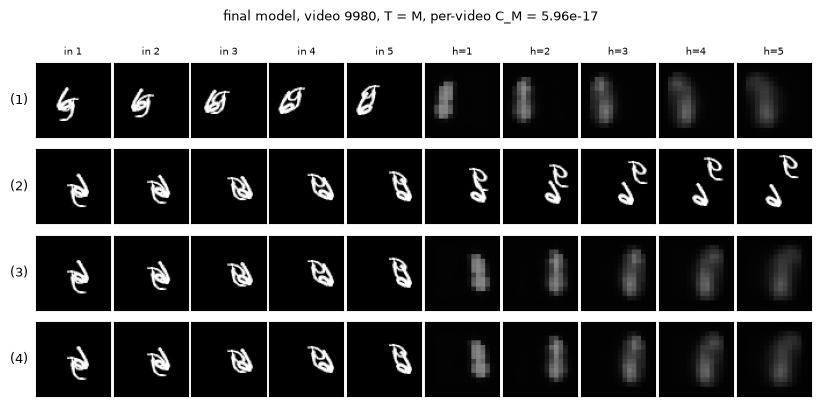

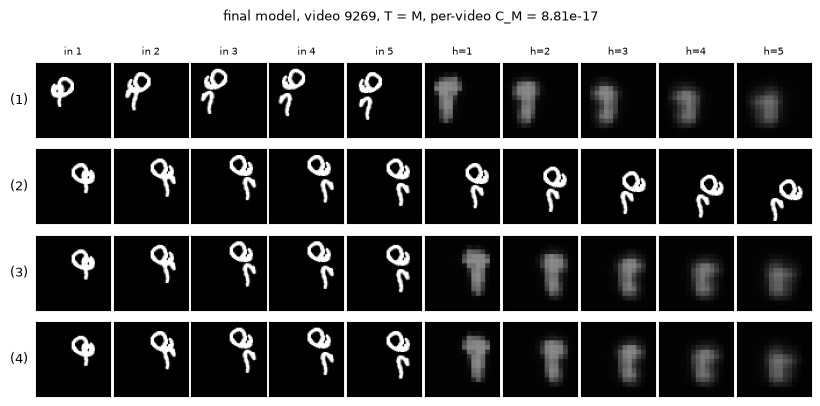

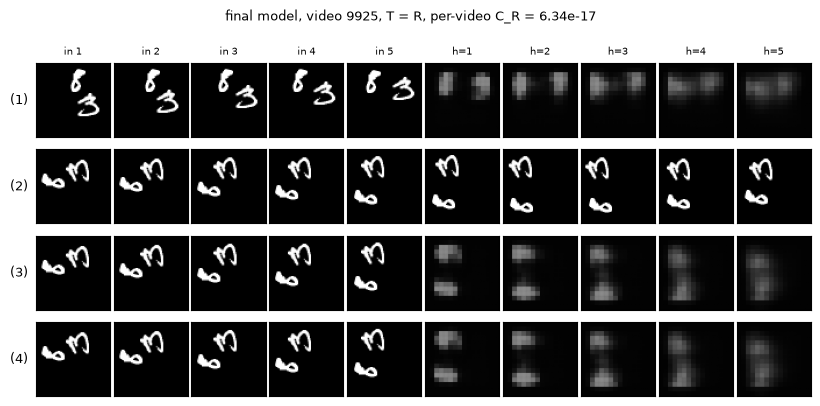

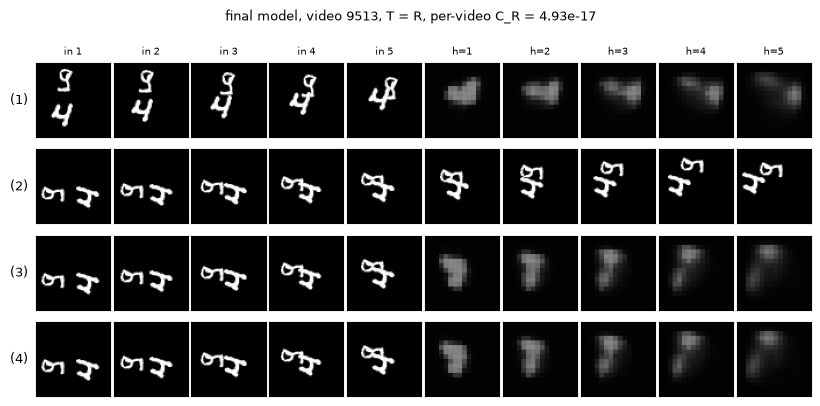

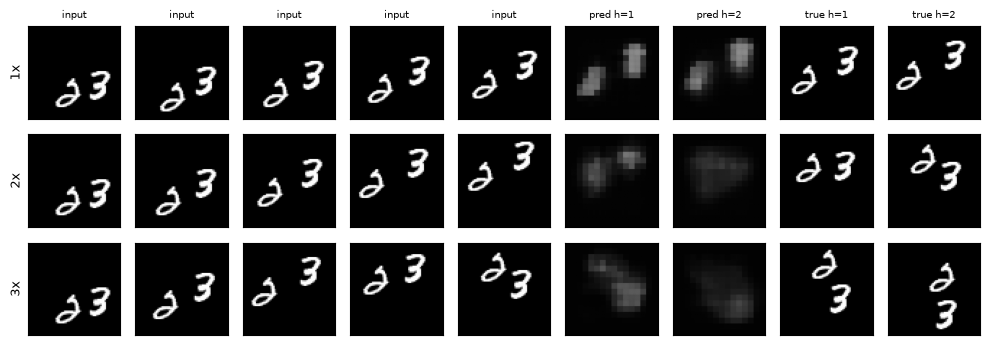

In [19]:
fk = f"sym{FINAL}_s0"
for key, T in [("C_M", mirror), ("C_R", rotate)]:
    for n, i in enumerate(fv["fig3_marks"][key]):
        rows4 = V.four_rows(X1[i], Y1[i], preds[fk]["I"][i], preds[fk][key[-1]][i], T)
        label = f"final model, video {9000+i}, T = {key[-1]}, per-video {key} = {float(pv[fk][key][i]):.2e}"
        V.figure3_panel(rows4, label, FIG_DIR / f"fig6a_final_{key[-1]}{n+1}_video{9000+i}.png")
        V.gif(rows4, GIF_DIR / f"fig6a_final_{key[-1]}_video{9000+i}.gif")
V.figure5(W, preds[fk], fv["fig5_id"], FIG_DIR / "fig6b_final_speed.png");